In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dython.nominal import associations

In [2]:
df = pd.read_csv("../data/train.csv")
df

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
533460,223401000121,22,2206,220604,3,22,320,25,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
533461,363008001011,36,3611,361103,3,22,500,24,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone
533462,303701001001,30,3003,300306,1,8,100,9,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Attached-1 side,Rectangular,Grade 3,has_superstructure_mud_mortar_stone
533463,284601000031,28,2803,280303,2,2,877,23,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 3,has_superstructure_mud_mortar_stone


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [5]:
df.describe()

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq
count,5.334650e+05,533465.000000,533465.000000,533465.000000,533465.000000,533465.000000,533465.000000,533465.000000
mean,2.607139e+11,25.764134,2582.312433,258236.686092,2.088000,24.337319,406.523453,16.047675
std,5.806563e+10,5.812230,581.640567,58164.132189,0.655001,64.999055,226.610477,5.490926
min,1.201010e+11,12.000000,1201.000000,120101.000000,1.000000,0.000000,70.000000,6.000000
25%,2.219060e+11,22.000000,2204.000000,220401.000000,2.000000,9.000000,280.000000,12.000000
50%,2.463010e+11,24.000000,2410.000000,241004.000000,2.000000,16.000000,358.000000,16.000000
75%,3.036070e+11,30.000000,3010.000000,301005.000000,2.000000,27.000000,470.000000,18.000000
max,3.667090e+11,36.000000,3611.000000,361108.000000,9.000000,999.000000,5000.000000,99.000000


In [6]:
df.isnull().sum()

building_id               0
district_id               0
vdcmun_id                 0
ward_id                   0
count_floors_pre_eq       0
age_building              0
plinth_area_sq_ft         0
height_ft_pre_eq          0
land_surface_condition    0
foundation_type           0
roof_type                 0
ground_floor_type         0
other_floor_type          0
position                  0
plan_configuration        0
damage_grade              0
superstructure            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [3]:
num_cols = df.select_dtypes(include=['number']).columns

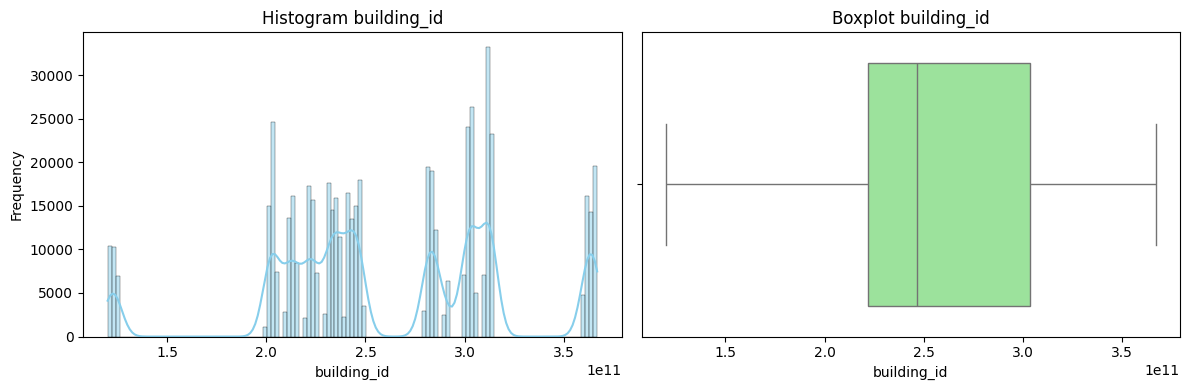

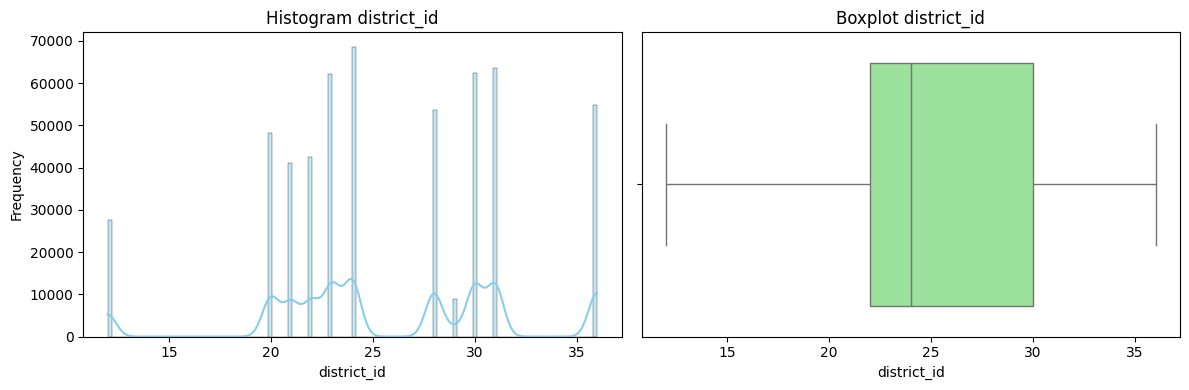

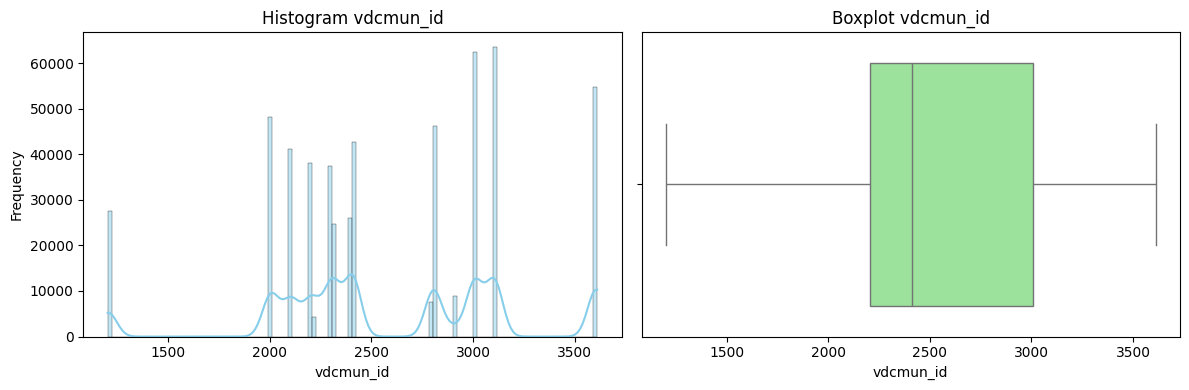

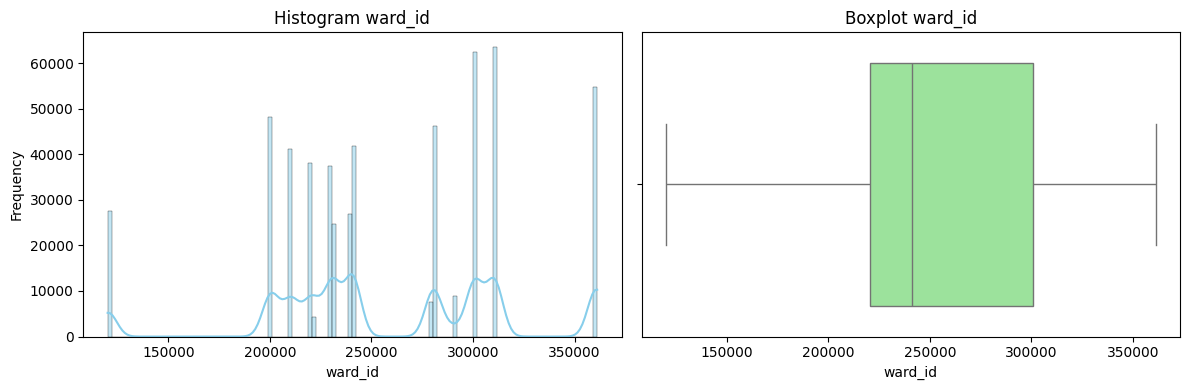

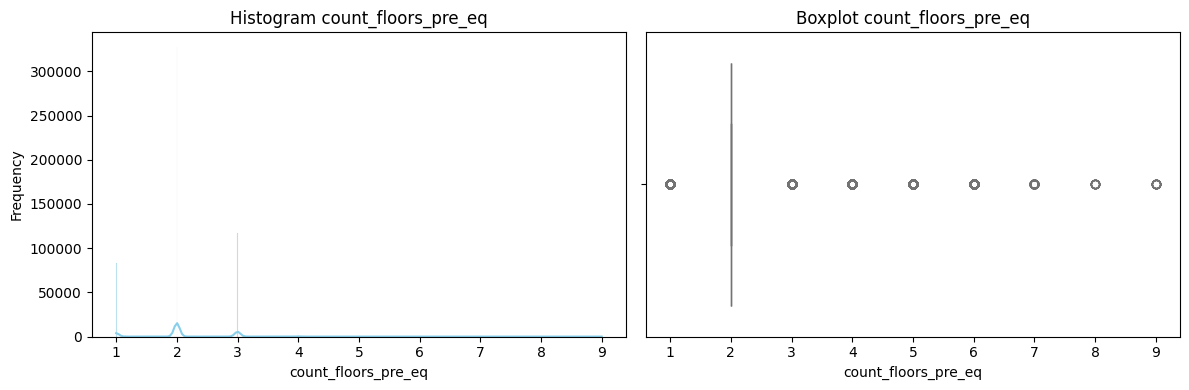

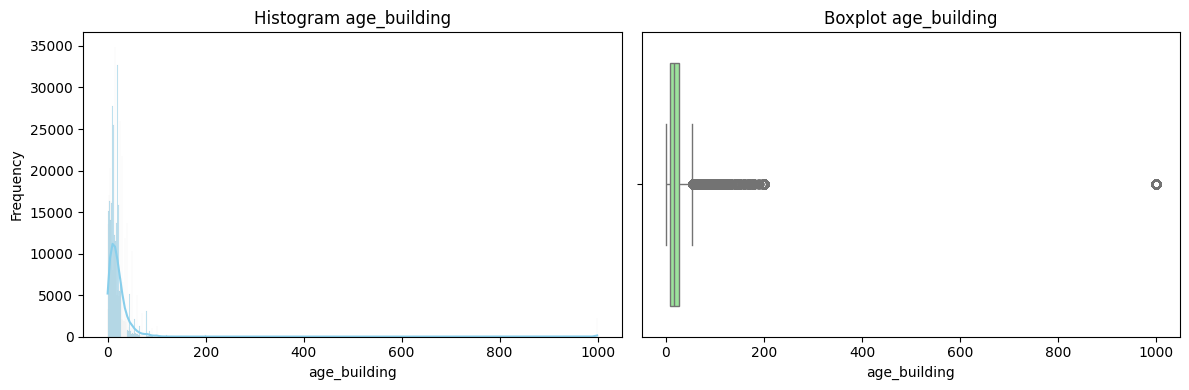

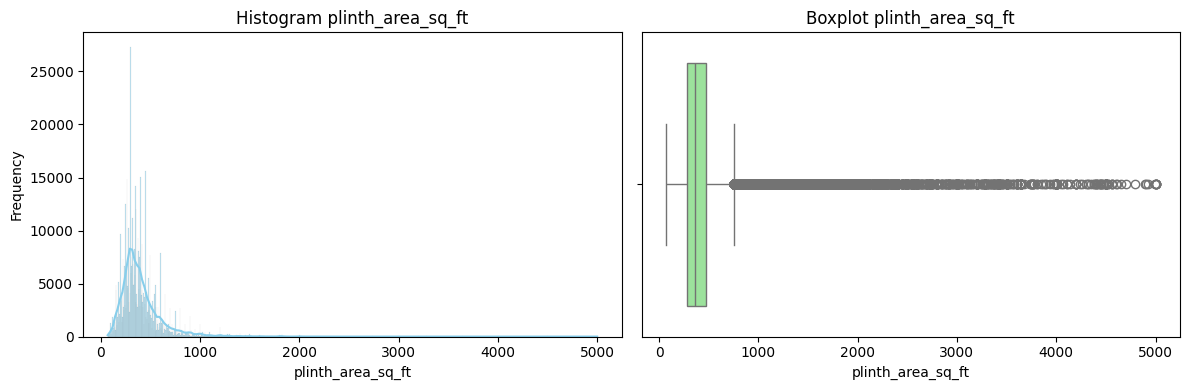

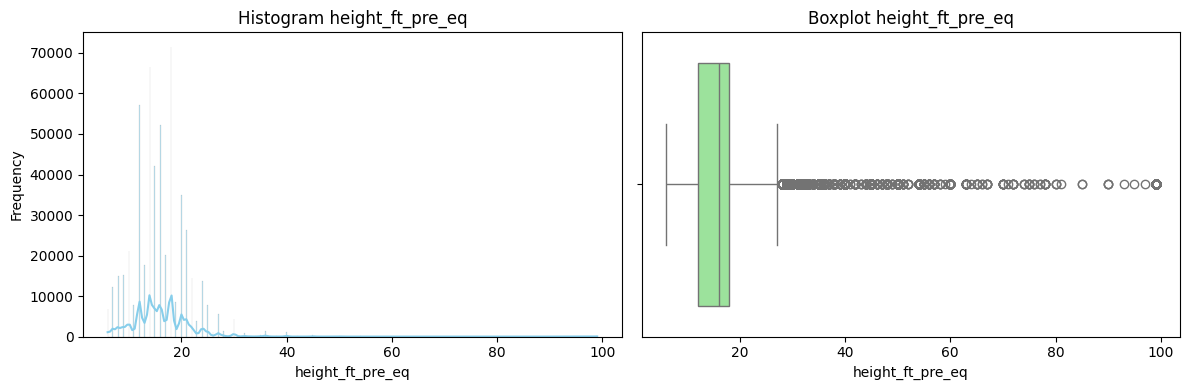

In [8]:
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12,4))

    sns.histplot(df[col], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histogram {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')

    sns.boxplot(x=df[col], ax=axes[1], color='lightgreen')
    axes[1].set_title(f"Boxplot {col}")
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()




In [9]:
# Daftar kolom yang ingin dicek
cols_to_check = ['building_id', 'district_id', 'vdcmun_id', 'ward_id']

# 1. Cek jumlah baris vs jumlah unique value untuk setiap kolom
for col in cols_to_check:
    if col in df.columns:
        total_rows = len(df)
        unique_count = df[col].nunique()
        
        print(f"Kolom: {col}")
        print(f" - Total Baris : {total_rows}")
        print(f" - Jumlah Unik : {unique_count}")
        
        if unique_count == total_rows:
            print(f" -> KESIMPULAN: '{col}' adalah UNIQUE ID (100% unik, tidak ada duplikat).\n")
        else:
            print(f" -> KESIMPULAN: '{col}' BUKAN UNIQUE ID (ada nilai yang muncul lebih dari 1 kali).\n")

Kolom: building_id
 - Total Baris : 533465
 - Jumlah Unik : 533465
 -> KESIMPULAN: 'building_id' adalah UNIQUE ID (100% unik, tidak ada duplikat).

Kolom: district_id
 - Total Baris : 533465
 - Jumlah Unik : 11
 -> KESIMPULAN: 'district_id' BUKAN UNIQUE ID (ada nilai yang muncul lebih dari 1 kali).

Kolom: vdcmun_id
 - Total Baris : 533465
 - Jumlah Unik : 110
 -> KESIMPULAN: 'vdcmun_id' BUKAN UNIQUE ID (ada nilai yang muncul lebih dari 1 kali).

Kolom: ward_id
 - Total Baris : 533465
 - Jumlah Unik : 945
 -> KESIMPULAN: 'ward_id' BUKAN UNIQUE ID (ada nilai yang muncul lebih dari 1 kali).



In [4]:
cols_to_check = ['building_id', 'district_id', 'vdcmun_id', 'ward_id']
for col in cols_to_check:
    df[col] = df[col].astype('str')

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  str  
 1   district_id             533465 non-null  str  
 2   vdcmun_id               533465 non-null  str  
 3   ward_id                 533465 non-null  str  
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [5]:
cat_cols = df.select_dtypes(include=['str']).columns
cat_cols = cat_cols.drop('building_id')
cat_cols

Index(['district_id', 'vdcmun_id', 'ward_id', 'land_surface_condition',
       'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type',
       'position', 'plan_configuration', 'damage_grade', 'superstructure'],
      dtype='str')

In [20]:
df['position'].value_counts()

position
Not attached       423151
Attached-1 side     90493
Attached-2 side     18943
Attached-3 side       878
Name: count, dtype: int64

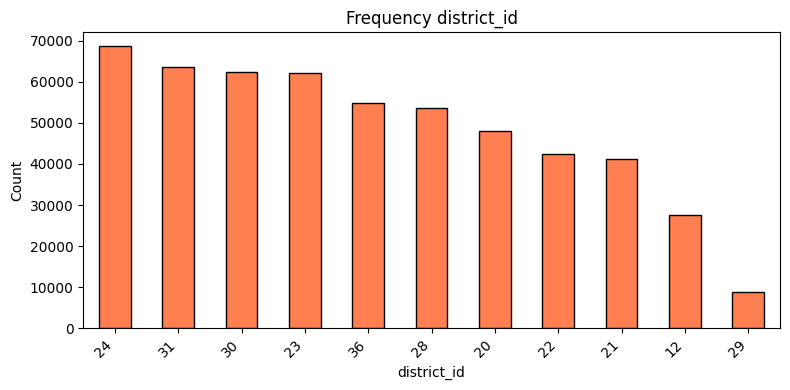

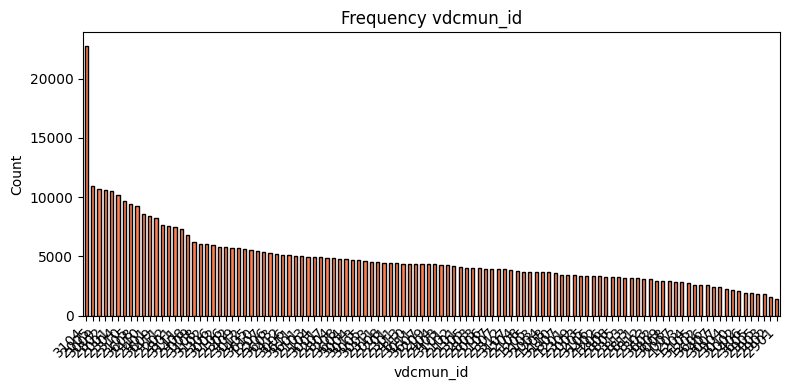

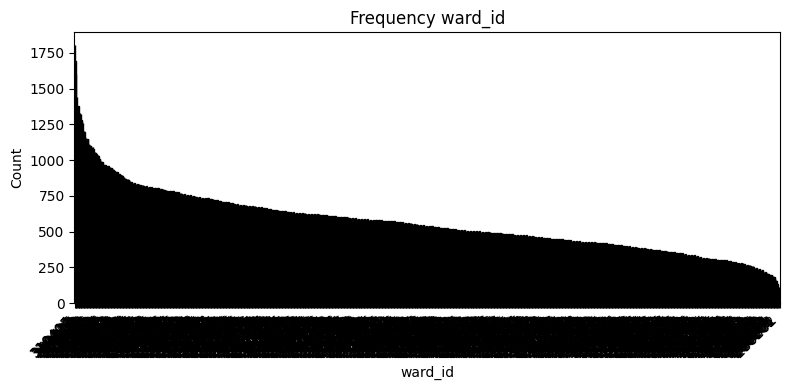

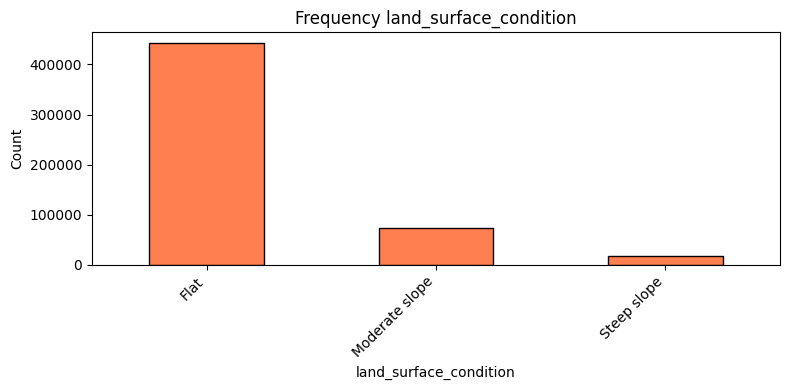

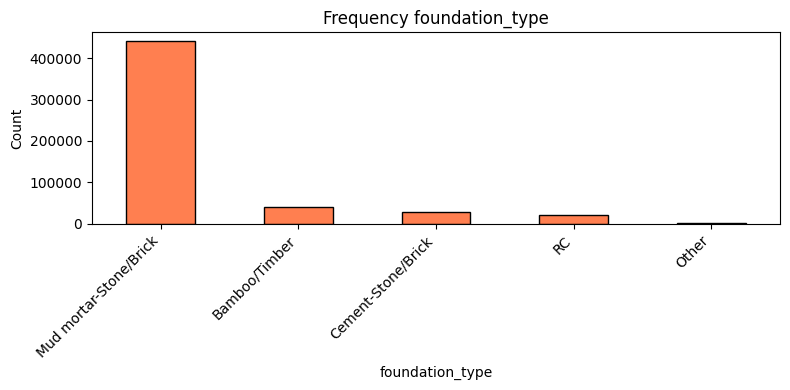

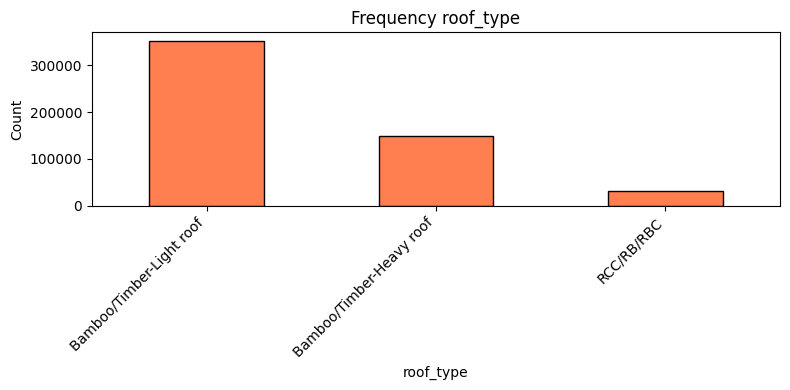

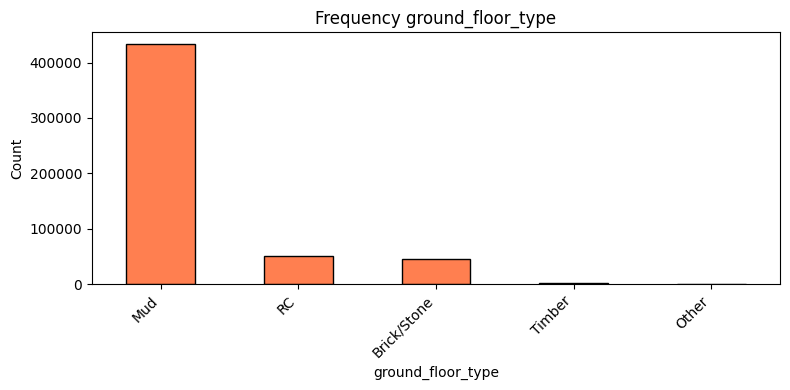

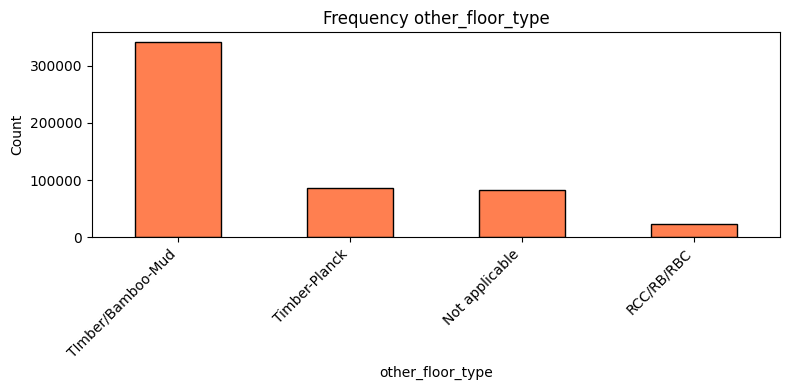

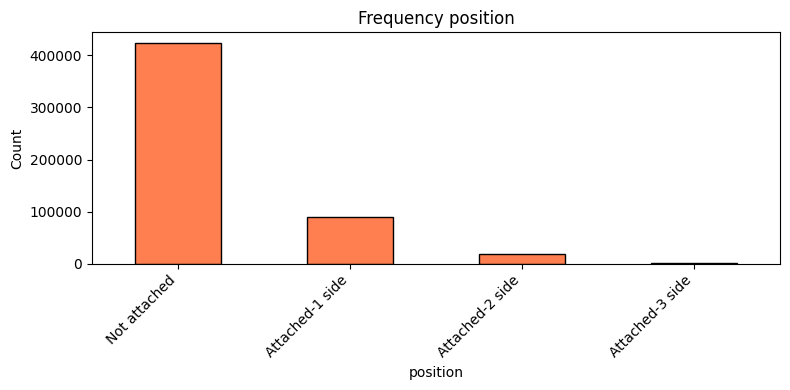

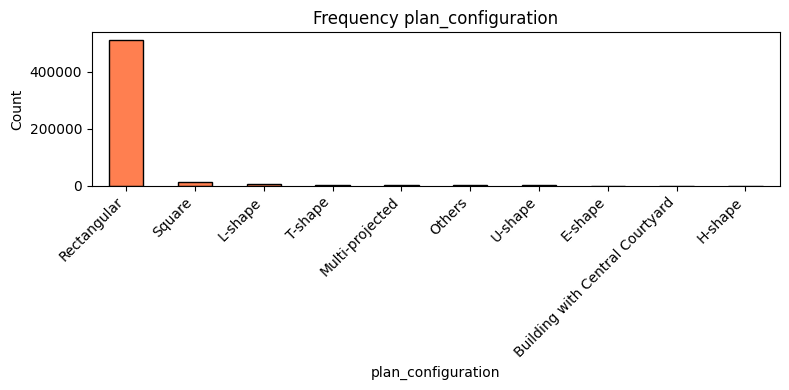

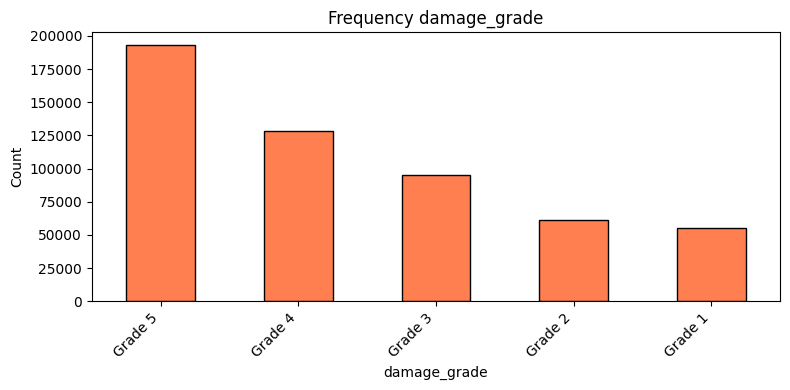

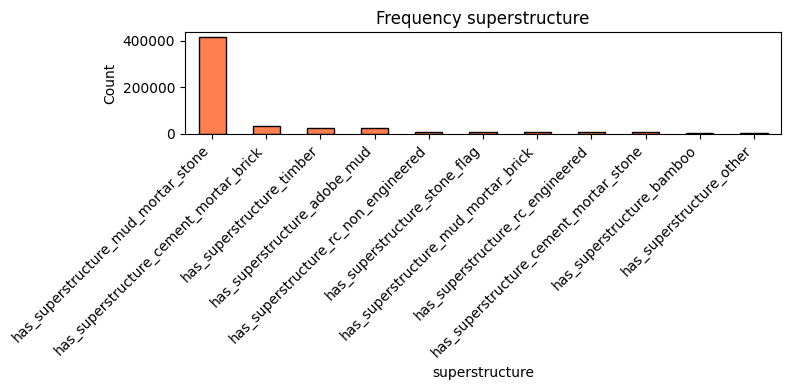

In [21]:
for col in cat_cols:
    plt.figure(figsize=(8,4))

    df[col].value_counts().plot(kind='bar', color='coral', edgecolor='black')

    plt.title(f'Frequency {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

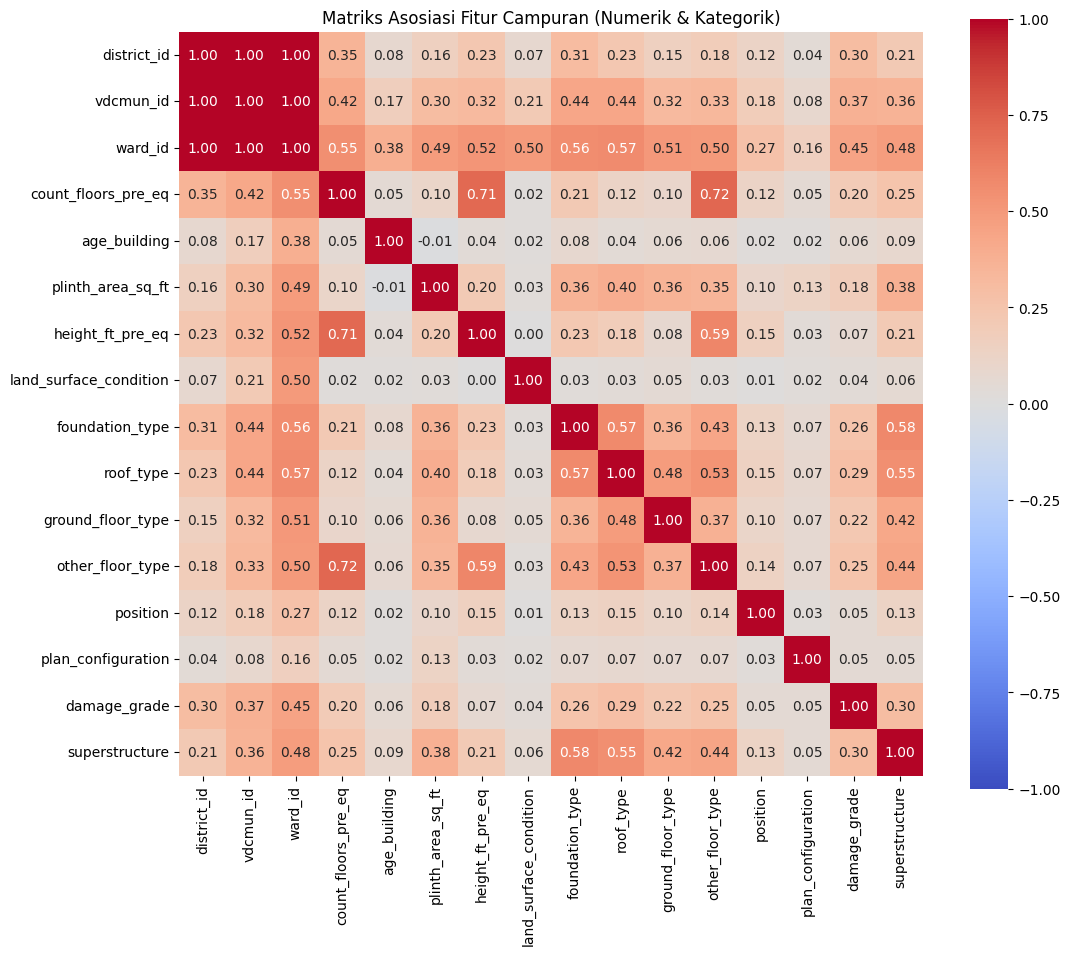

                        district_id  vdcmun_id   ward_id  count_floors_pre_eq  \
district_id                1.000000   0.999907  0.999124             0.353424   
vdcmun_id                  0.999907   1.000000  0.999217             0.423626   
ward_id                    0.999124   0.999217  1.000000             0.546905   
count_floors_pre_eq        0.353424   0.423626  0.546905             1.000000   
age_building               0.077993   0.170460  0.383477             0.047865   
plinth_area_sq_ft          0.155268   0.303557  0.488195             0.101967   
height_ft_pre_eq           0.228681   0.316291  0.522048             0.711848   
land_surface_condition     0.074864   0.208967  0.495765             0.021671   
foundation_type            0.305932   0.435756  0.562145             0.211118   
roof_type                  0.230883   0.435711  0.566397             0.124708   
ground_floor_type          0.154059   0.317700  0.506464             0.097091   
other_floor_type           0

In [19]:
results = associations(
    df.drop('building_id', axis=1),
    nominal_columns=cat_cols,
    numerical_columns=None,
    cmap='coolwarm',
    figsize=(12, 10),
    title="Matriks Asosiasi Fitur Campuran (Numerik & Kategorik)",
    plot=True
)

# Mengambil tabel matriks korelasinya dalam bentuk DataFrame
corr_matrix = results['corr']
print(corr_matrix)

In [35]:
for col in num_cols:
    print(f"min {col}: {df[col].min()}")
    print(f"max {col}: {df[col].max()}")

min building_id: 120101000011
max building_id: 366709001251
min district_id: 12
max district_id: 36
min vdcmun_id: 1201
max vdcmun_id: 3611
min ward_id: 120101
max ward_id: 361108
min count_floors_pre_eq: 1
max count_floors_pre_eq: 9
min age_building: 0
max age_building: 200
min plinth_area_sq_ft: 70
max plinth_area_sq_ft: 5000
min height_ft_pre_eq: 6
max height_ft_pre_eq: 99


In [6]:
df = df[df['age_building'] != 999]

In [8]:
for col in cat_cols:
    print(f"Unique values in {col}: {df[col].nunique()}")
    print(df[col].value_counts())
    print("\n")

Unique values in district_id: 11
district_id
24    67911
31    63092
30    62306
23    62005
36    54551
28    53538
20    48131
22    42351
21    41034
12    27595
29     8753
Name: count, dtype: int64


Unique values in vdcmun_id: 110
vdcmun_id
3104    22640
2005    10946
3009    10686
2802    10589
2001    10510
        ...  
3605     1906
2905     1842
2903     1696
2902     1569
2901     1410
Name: count, Length: 110, dtype: int64


Unique values in ward_id: 945
ward_id
310405    1803
310404    1692
310412    1599
200506    1442
310419    1380
          ... 
360501     156
290204     134
360601     113
290202     110
280801     108
Name: count, Length: 945, dtype: int64


Unique values in land_surface_condition: 3
land_surface_condition
Flat              440096
Moderate slope     73757
Steep slope        17414
Name: count, dtype: int64


Unique values in foundation_type: 5
foundation_type
Mud mortar-Stone/Brick    438127
Bamboo/Timber              40143
Cement-Stone/Brick         